# Markov Chains and Tumor Heterogeneity


## Background

Why are tumors so hard to treat? Why have we been fighting the "War on Cancer" for over 50 years? 

One key reason is that a tumor isn't made up of a single kind of cell. If it was, we could find a single drug that would target said cell, and kill all of them, without them coming back. However, most tumors are mixes of different types of cancer cells. A breast cancer tumor will only contain breast tumor cells, but those breast tumor cells may be clustered in different states-- some of which are sensitive to drugs, some of which are naturally resistant, and some of which can transition from one state to another. In fact, drug treatment is often the *force* that helps tumor cells transition from sensitive to resistant, meaning the treatment itself is worsening the disease it is trying to treat.

## The lab goal: 
>**Simulate a patient's tumor and figure out what combination of drugs is likely to be effective at killing the tumor.**

If we can track how cells change state *within a single tumor* under drugs, then we can predict what might happen to a patient treated with said drug. To answer that we need to know **how often a cell in each state moves to each other state during one treatment cycle**. That is a transition matrix, and a transition matrix lets us forecast what any tumor looks like after many cycles.

In this lab you will:
   
1. **Build a transition matrix.** Use lineage tags to match each cell at time point A to its descendant at time point B, then count and normalize.
2. **Evolve a distribution.** Start from each single state, and from a mixed tumor, and see where each one ends up.
3. **Simulate random walks and whole tumors.** Follow individual cells by drawing random numbers, then simulate many tumors to estimate how likely each one is to be cured or to relapse.
4. **Find which tumors each drug can cure**, and see why a mixed tumor can't be cured by either drug alone.


Note: **The data is simulated.** The states and their marker genes are modelled on PC9 cells (Oren et al. 2021, *Nature* 596:576), but every count was generated by a script, and how each state responds to each drug is vastly simplified.

## The data

**A little background:**

Lung cancer cells carry a mutant EGFR gene and depend on it to grow. We compare two
drugs:

- **osimertinib**, which blocks EGFR, and
- **docetaxel**, a chemotherapy that kills cells while they divide.
- We will also look at how the cells evolve under no treatment ("drug holiday")

You do not need to understand biology or cancer to complete this lab; the key thing is you have drugs with different effects on cells within a single tumor.

**The dataset:**

Every cell carries something called a  **lineage tag**: a short DNA barcode inserted into its genome, inherited by its descendants. For each drug, one sample is:

1. sequenced at **time point A**, before treatment;
2. treated for **one cycle**;
3. sequenced again at **time point B**.

A tag that appears at both time points links a cell at A to its descendant at B. **A tag seen at A but missing at B means that cell died.** We make one big simplifying assumption: each tag maps one cell at A to *at most one* cell at B.


In [1]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

rng = np.random.default_rng(5030)
plt.rcParams["figure.dpi"] = 110

In [2]:
STATE_ORDER = ["S-G1", "S-syn", "S-G2M", "P",
           "NCP", "CP", "MDR"] 
STATE_COLORS = dict(zip(STATE_ORDER, sns.color_palette("Set2", len(STATE_ORDER))))
STATE_COLORS["cleared"] = "#8a8984"  

In [3]:
cells = pd.read_csv("cell_data.csv")
cells.head()

,Unnamed: 0,experiment,timepoint,lineage_tag,umap_x,umap_y,state
0,0,osimertinib,A,tago-02305,14.189159,7.205170,S-G1
1,1,osimertinib,B,tago-01560,1.031097,13.491245,P
2,2,osimertinib,A,tago-02253,14.651874,7.435656,S-G1
3,3,osimertinib,A,tago-01478,13.919818,-3.705924,S-syn
4,4,osimertinib,A,tago-02626,14.527276,6.953301,S-G1


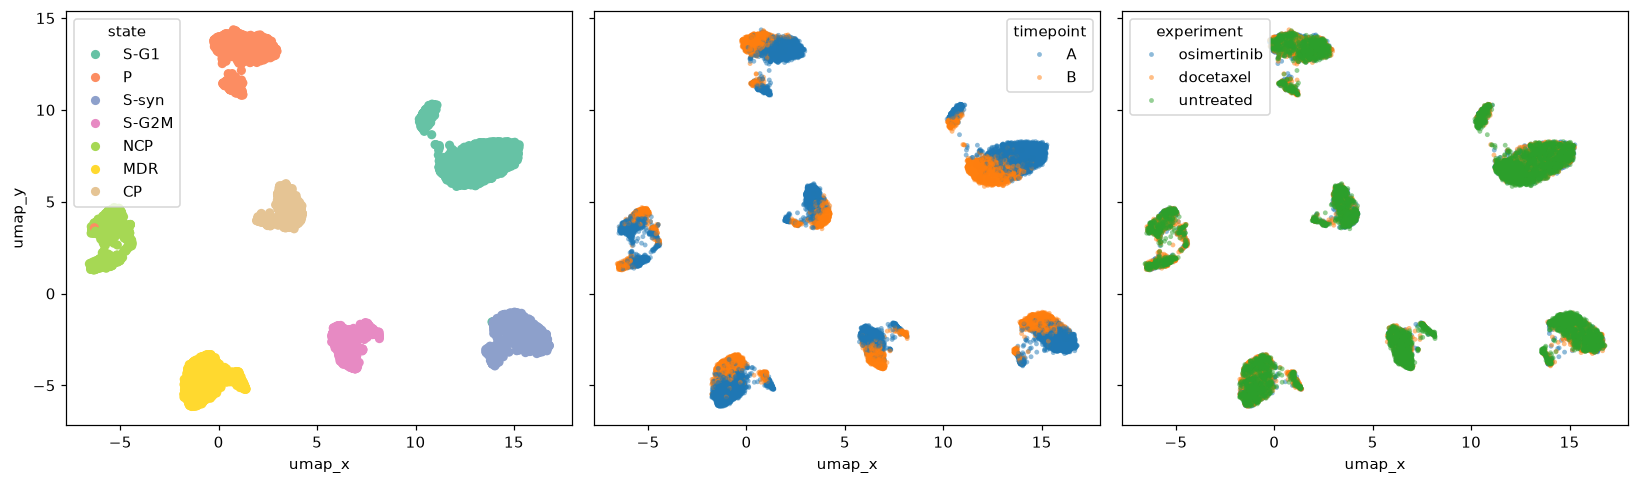

In [4]:
import seaborn as sns
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5), sharex=True, sharey=True)
sns.scatterplot(cells, x = "umap_x", y ="umap_y", hue = "state", ax = axes[0], palette = "Set2", linewidth=0)
sns.scatterplot(cells, x = "umap_x", y ="umap_y", hue = "timepoint", ax = axes[1],s=10, alpha=0.5, linewidth=0)
sns.scatterplot(cells, x = "umap_x", y ="umap_y", hue = "experiment", ax = axes[2],s=10, alpha=0.5, linewidth=0)
plt.tight_layout()
plt.show()

<img src="state_diagram_v2.png">

## 2. Build the transition matrix for the Osimertinib experiment

Start with the osimertinib experiment.

A transition matrix $P$ has one row per state at time point A and one column
per state at time point B:

$$
P_{ij} \;=\; \Pr[\,X_{t+1} = j \mid X_t = i\,]
\;\approx\; \frac{\#\{\text{cells in state } i \text{ at A whose tag is in state } j \text{ at B}\}}
                 {\#\{\text{cells in state } i \text{ at A}\}}.
$$

In the code below, we will start with just the osimertinib experiment (timepoints A and B), and look at where each tag was in A and where it moved to in B. 

**Where does a cell that died end up?** We add an eighth outcome, `"cleared"`, for tags present at A and missing at B.

In [5]:
osi = cells[cells["experiment"] == "osimertinib"]
at_A = osi[osi.timepoint == "A"][["lineage_tag", "state"]]
at_B = osi[osi.timepoint == "B"][["lineage_tag", "state"]]

pairs = pd.merge(at_A, at_B, on="lineage_tag", how="left", suffixes=("_A", "_B"))
pairs["state_B"] = pairs["state_B"].fillna("cleared")

pairs.head()

,lineage_tag,state_A,state_B
0,tago-02305,S-G1,cleared
1,tago-02253,S-G1,cleared
2,tago-01478,S-syn,NCP
3,tago-02626,S-G1,P
4,tago-01487,P,P


In [6]:
STATES = [s for s in STATE_ORDER if s in set(cells["state"])]   # states in a fixed order
OUTCOMES = STATES + ["cleared"]
counts = (pd.crosstab(pairs.state_A, pairs.state_B)
            .reindex(index=STATES, columns=OUTCOMES, fill_value=0))
P_hat = counts.div(counts.sum(axis=1), axis=0)

In [7]:
assert np.allclose(P_hat.sum(axis=1), 1), "Every row should sum to 1."


In [8]:
print("transition counts:")
display(counts)
print("estimated transition matrix (osimertinib, one cycle):")
P_hat.round(3)

transition counts:


state_B,S-G1,S-syn,S-G2M,P,NCP,CP,MDR,cleared
state_A,,,,,,,,
S-G1,91,17,11,154,41,0,0,437
S-syn,27,23,17,38,16,0,0,333
S-G2M,8,13,20,20,0,0,0,219
P,47,11,8,160,75,0,0,154
NCP,19,0,0,31,153,0,0,109
CP,0,0,0,0,0,279,0,0
MDR,20,14,10,14,0,0,82,329


estimated transition matrix (osimertinib, one cycle):


state_B,S-G1,S-syn,S-G2M,P,NCP,CP,MDR,cleared
state_A,,,,,,,,
S-G1,0.121,0.023,0.015,0.205,0.055,0.0,0.000,0.582
S-syn,0.059,0.051,0.037,0.084,0.035,0.0,0.000,0.733
S-G2M,0.029,0.046,0.071,0.071,0.000,0.0,0.000,0.782
P,0.103,0.024,0.018,0.352,0.165,0.0,0.000,0.338
NCP,0.061,0.000,0.000,0.099,0.490,0.0,0.000,0.349
CP,0.000,0.000,0.000,0.000,0.000,1.0,0.000,0.000
MDR,0.043,0.030,0.021,0.030,0.000,0.0,0.175,0.701


Because some of the cells die and get cleared, we added an extra state they could move to. To use this transition matrix over and over again (for example, if a patient got two rounds of osimertinib), we need it to have the *same* rows and columns-- **the transition matrix should be able to tell us where a cell moves to for *any state at all, including "cleared."*** So we will **add another row to the transition matrix:** if a cell starts in "cleared" it stays cleared with probability = 1.

### Make it square

We add that row by **assumption**: a cleared cell stays cleared with probability 1. A state you can never leave is called an **absorbing state**.

In [9]:
#add a cleared row that stays cleared with p = 1
P_hat.loc["cleared"] = pd.Series({rowname: (1 if rowname == "cleared" else 0) for rowname in P_hat.columns})

In [10]:
STATES = [s for s in STATE_ORDER if s in set(cells["state"])]
OUTCOMES = STATES + ["cleared"]

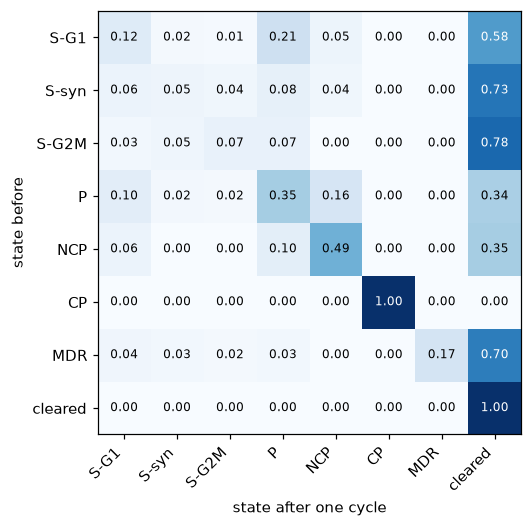

In [11]:
def show_matrix(P, title=None, ax=None):
    ax = ax or plt.subplots(figsize=(6.5, 5))[1]
    values = P.to_numpy()                      # numbers for imshow and P[i, j]
    ax.imshow(values, cmap="Blues", vmin=0, vmax=1)
    for i in range(values.shape[0]):
        for j in range(values.shape[1]):
            ax.text(j, i, f"{values[i, j]:.2f}", ha="center", va="center",
                    color="white" if values[i, j] > 0.5 else "black", fontsize=8)
    ax.set_xticks(range(values.shape[1]), P.columns, rotation=45, ha="right")
    ax.set_yticks(range(values.shape[0]), P.index)
    ax.set_xlabel("state after one cycle"); ax.set_ylabel("state before")
    ax.set_title(title)

show_matrix(P_hat)

<div class='alert alert-info'>
<b>Question:</b> reading P_hat and looking at the matrix, are any of the measured states other than "cleared" also (approximately) absorbing under osimertinib? If so, what does this mean in terms of the response to drug treatment? If not, what does it mean?
</div>

Under Osimertinib, the transition matrix shows two absorbing states: cleared and CP, whos row is one the diagonal with zeroes elsewhere. Every other state is well below zero, meaning that the meaning the chain eventually leaves it, and mostly flows into "cleared". 

Cells in the CP to Cleared present a probability of zero, so CP cells are eliminated. 

## 3. Simulate a tumor comprising 1 cell type: Evolve a distribution

Write the state of the whole tumor as a **row vector** $\pi_t$: entry $j$ is the
probability that a randomly chosen original cell is in state $j$ after $t$
cycles. One cycle multiplies by $P$:

$$
\pi_{t+1} = \pi_t P
\qquad\Longrightarrow\qquad
\pi_t = \pi_0 P^t .
$$

Start with the simplest $\pi_0$: a **basis vector**, all probability on one
state. $e = (1, 0, 0, 0, 0, 0, 0, 0)$ asks "what happens to a
cell that starts in state S-G1?" Equivalently, "what happens to a tumor made entirely of S-G1 cells?"

**Predict first.** Before running the code: look at the transition matrix: which starting states can osimertinib eliminate completely? Which can't it? 

In [12]:
def evolve(pi0, P, n_cycles):
    '''Return an array of shape (n_cycles + 1, n_states) whose row t is pi0 @ P^t.'''
    traj = [np.asarray(pi0, dtype=float)]
    for _ in range(n_cycles):
        traj.append(traj[-1] @ P)
    return np.array(traj)

In [13]:
def basis(starting_state, P):
    '''All probability on one state, named as in P's columns.'''
    names = list(P.columns)
    e = np.zeros(len(names))
    e[names.index(starting_state)] = 1.0
    return e

basis("S-G1", P_hat)

array([1., 0., 0., 0., 0., 0., 0., 0.])

### What happens after many rounds of a single treatment?
We are going to run 8 rounds of treatment. A typical course of chemotherapy is 4 to 8 rounds, so this is on the higher end. With 8 rounds, do we clear all of the cancer cells?

In [14]:
traj = evolve(basis("S-G1", P_hat), P_hat, 8)
pd.DataFrame(traj, columns=OUTCOMES).round(3)

,S-G1,S-syn,S-G2M,P,NCP,CP,MDR,cleared
0,1.000,0.000,0.000,0.000,0.000,0.0,0.0,0.000
1,0.121,0.023,0.015,0.205,0.055,0.0,0.0,0.582
2,0.041,0.010,0.007,0.105,0.068,0.0,0.0,0.769
3,0.021,0.004,0.003,0.054,0.053,0.0,0.0,0.865
4,0.012,0.002,0.002,0.029,0.036,0.0,0.0,0.919
5,0.007,0.001,0.001,0.016,0.023,0.0,0.0,0.951
6,0.004,0.001,0.000,0.010,0.015,0.0,0.0,0.971
7,0.002,0.000,0.000,0.006,0.009,0.0,0.0,0.982
8,0.001,0.000,0.000,0.003,0.005,0.0,0.0,0.989


The output of the evolve function is a dataframe where columns are the states and each row is the distribution of probability after that many cycles. We can also visualize this in the plots below. 

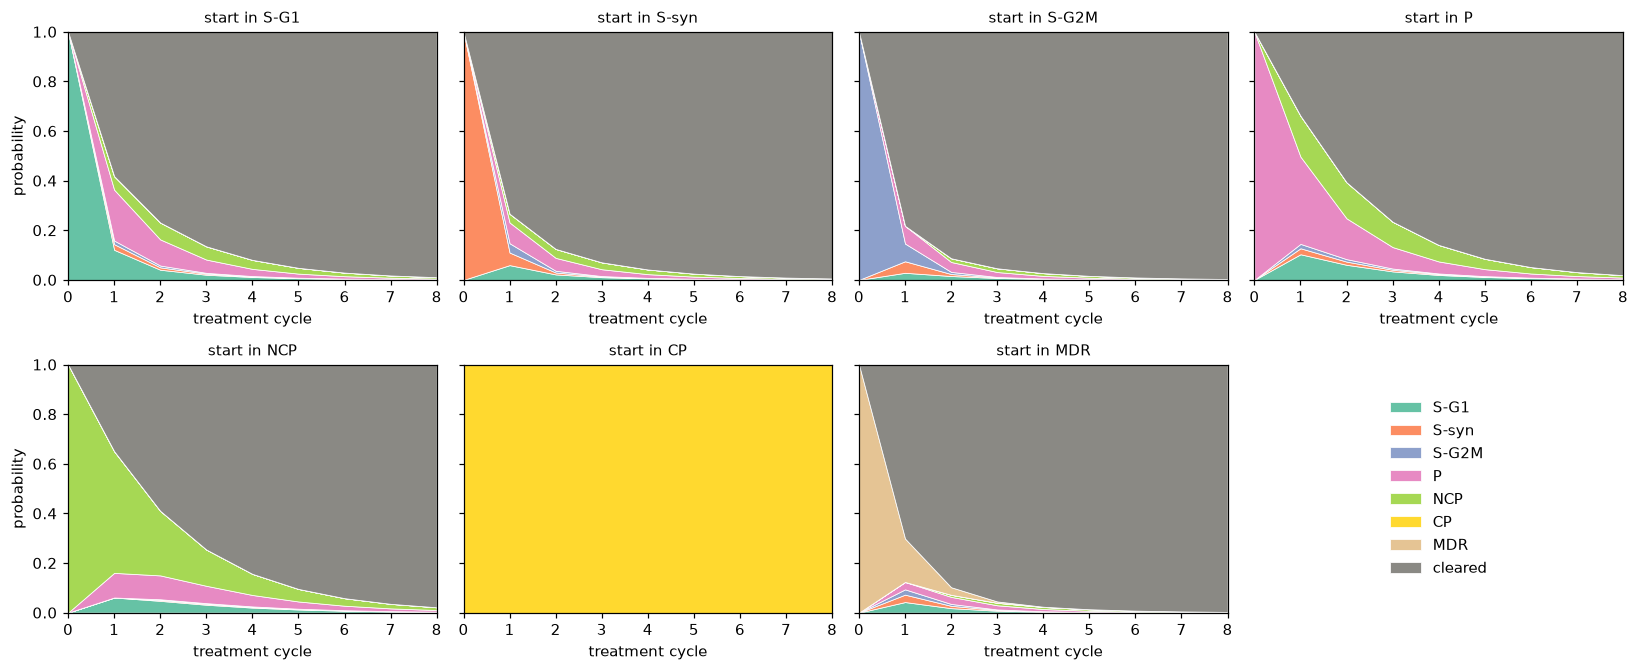

fraction alive after 4 cycles, starting in S-G1 : 0.081
fraction alive after 4 cycles, starting in S-syn : 0.042
fraction alive after 4 cycles, starting in S-G2M : 0.027
fraction alive after 4 cycles, starting in P : 0.141
fraction alive after 4 cycles, starting in NCP : 0.156
fraction alive after 4 cycles, starting in CP : 1.0
fraction alive after 4 cycles, starting in MDR : 0.024
fraction alive after 4 cycles, starting in cleared : 0.0


In [15]:
def plot_trajectory(traj, ax, title):
    t = np.arange(len(traj))
    ax.stackplot(t, traj.T, labels=OUTCOMES, colors=[STATE_COLORS[o] for o in OUTCOMES],
                 edgecolor="white", linewidth=0.5)
    ax.set_xlim(0, t[-1]); ax.set_ylim(0, 1)
    ax.set_title(title, fontsize=10); ax.set_xlabel("treatment cycle")

N_CYCLES = 8
fig, axes = plt.subplots(2, 4, figsize=(15, 6.2), sharey=True)
for ax, s in zip(axes.flat, STATES):
    plot_trajectory(evolve(basis(s, P_hat), P_hat, N_CYCLES), ax, f"start in {s}")

axes.flat[-1].axis("off")                                   # 7 states, 8 panels: use the last one for the legend
handles, labels = axes.flat[0].get_legend_handles_labels()
axes.flat[-1].legend(handles, labels, loc="center", frameon=False)

for ax in axes[:, 0]:
    ax.set_ylabel("probability")
plt.tight_layout()
plt.show()

alive3 = {s: 1 - evolve(basis(s, P_hat), P_hat, 4)[-1, -1] for s in OUTCOMES}
for s,v in alive3.items():
    print("fraction alive after 4 cycles, starting in", s, ":", round(v, 3))

<div class='alert alert-info'>
Use code as appropriate to answer the following questions.

- Which starting states does osimertinib completely eliminate (all probability ends in `cleared`)? Which ones survive?
- Of the states that can be cleared, which tumor lasts the longest?
- Which starting state sticks around for the most cycles of drug?
- Which starting state results in the highest proportion of alive cells after three cycles?</div>



Every state other than CP is completely eliminated. We can see from the graph and value that the CP never goes away (fully yellow graph). 

NCP is expected to last the longest. We can see the curve of this graph is the least steep as it approaches 0. P has a similar length until it is fully cleared, but it seems to transition to NCP before getting fully cleared. 

CP never leaves, meaning it sticks around for the most cycles of the drug. 

CP has the highest proportion of alive cells after 3 cycles, since it never goes away. NCP had the highest proportion of alive cells for the states that are able to be cleared. NCP is followed closely by P. 


### Starting from a mix of cell types
Use the distribution of states in timepoint A across all three experiments as a starting vector, $\pi_{0}$. Use this as your starting vector to evolve, and plot the result.

In [17]:
A = cells[cells['timepoint'] == 'A']
counts = A['state'].value_counts().reindex(OUTCOMES, fill_value = 0)
pi_mix = (counts / counts.sum()).to_numpy()

print(pi_mix)

[0.247      0.14833333 0.09944444 0.15255556 0.10244444 0.09722222
 0.153      0.        ]


In [18]:
traj_mix = evolve(pi_mix, P_hat, 8)

pd.DataFrame(traj_mix, columns=OUTCOMES).round(3)

,S-G1,S-syn,S-G2M,P,NCP,CP,MDR,cleared
0,0.247,0.148,0.099,0.153,0.102,0.097,0.153,0.000
1,0.070,0.026,0.022,0.139,0.094,0.097,0.027,0.525
2,0.032,0.008,0.007,0.077,0.074,0.097,0.005,0.701
3,0.017,0.003,0.003,0.042,0.051,0.097,0.001,0.786
4,0.010,0.002,0.001,0.024,0.033,0.097,0.000,0.833
5,0.006,0.001,0.001,0.014,0.021,0.097,0.000,0.861
6,0.003,0.001,0.000,0.008,0.013,0.097,0.000,0.877
7,0.002,0.000,0.000,0.005,0.008,0.097,0.000,0.887
8,0.001,0.000,0.000,0.003,0.005,0.097,0.000,0.893


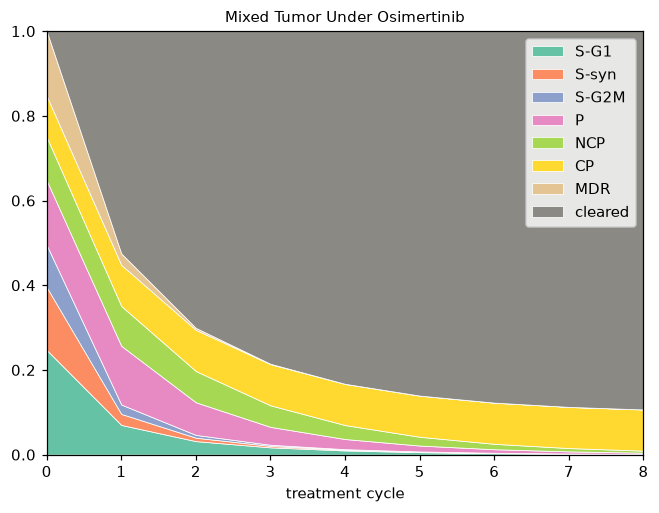

In [20]:
fig, ax = plt.subplots(figsize = (7, 5))

plot_trajectory(traj_mix, ax, "Mixed Tumor Under Osimertinib")
ax.legend()

plt.show()

<div class = "alert alert-info"> Which state ends up dominating the remaining cluster? Will these cells ever be cleared? How does the long-run endpoint relate to the transition matrix?</div>

CP dominates the cluster. The cells that started in CP will not clear since they are not cleared with Osimertinib. Since CP is an absorbing state, once a cell ends up there, it will never leave that state. Most of the other states don't really transition into CP, so the surviving cells are roughly the same as the starting fraction of CP cells. 

## 4. Transition matrices for docetaxel and the drug holiday

Using the same approach in step 2 and step 3, answer the following questions.

1. What is the transition matrix under docetaxel and drug holiday, and how do they compare to osimertinib? Are there any absorbing states?
2. Simulate the mixed tumor under multiple rounds of docetaxel. What happens?

In [21]:
##Add code here
# keep these as 8x8 numpy arrays (with the cleared row): the random walks index rows by position
P_osi = P_hat.to_numpy()

# Docetaxel
doc = cells[cells["experiment"] == "docetaxel"]

doc_A = doc[doc["timepoint"] == "A"]
doc_B = doc[doc["timepoint"] == "B"]

# Drug holiday
holiday = cells[cells["experiment"] == "untreated"]

holiday_A = holiday[holiday["timepoint"] == "A"]
holiday_B = holiday[holiday["timepoint"] == "B"]

# Docetaxel
pairs_doc = doc_A[["lineage_tag", "state"]].rename(
    columns={"state": "state_A"}
).merge(
    doc_B[["lineage_tag", "state"]].rename(
        columns={"state": "state_B"}
    ),
    on="lineage_tag",
    how="left"
)

pairs_doc["state_B"] = pairs_doc["state_B"].fillna("cleared")


# Drug holiday
pairs_holiday = holiday_A[["lineage_tag", "state"]].rename(
    columns={"state": "state_A"}
).merge(
    holiday_B[["lineage_tag", "state"]].rename(
        columns={"state": "state_B"}
    ),
    on="lineage_tag",
    how="left"
)


pairs_holiday["state_B"] = pairs_holiday["state_B"].fillna("cleared")

counts_doc = pd.crosstab(
    pairs_doc.state_A, pairs_doc.state_B
).reindex(index=STATES, columns=OUTCOMES, fill_value=0)

counts_holiday = pd.crosstab(
    pairs_holiday.state_A, pairs_holiday.state_B
).reindex(index=STATES, columns=OUTCOMES, fill_value=0)


#Doc and Holiday
P_doc = counts_doc.div(counts_doc.sum(axis=1), axis=0)

P_holiday = counts_holiday.div(counts_holiday.sum(axis=1), axis=0)

P_doc.loc["cleared"] = pd.Series({
    rowname: (1 if rowname == "cleared" else 0)
    for rowname in OUTCOMES
})
P_holiday.loc["cleared"] = pd.Series({
    rowname: (1 if rowname == "cleared" else 0)
    for rowname in OUTCOMES
})

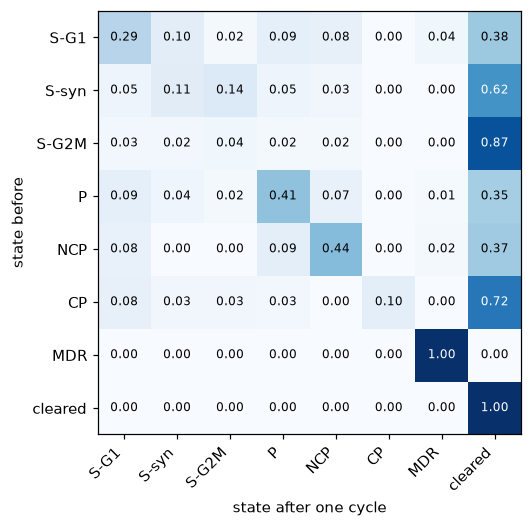

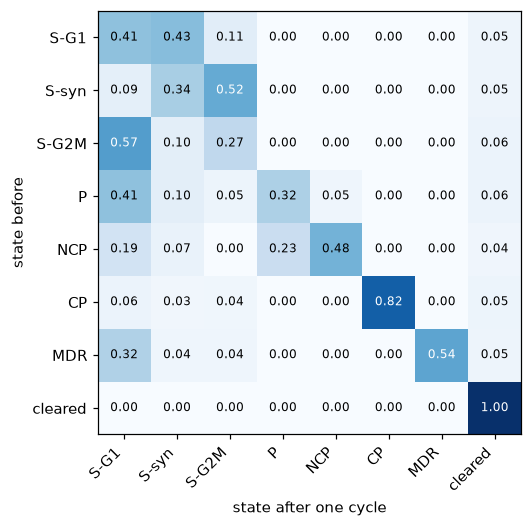

In [22]:
#Plot the transition matrices for docetaxel and the drug holiday.

show_matrix(pd.DataFrame(P_doc, index=OUTCOMES, columns=OUTCOMES))
show_matrix(pd.DataFrame(P_holiday, index=OUTCOMES, columns=OUTCOMES))

In [24]:
# Simulate the evolution of pi_mix under docetaxel 

traj_doc = evolve(pi_mix, P_doc, N_CYCLES)
pd.DataFrame(traj_doc, columns=OUTCOMES).round(3)

,S-G1,S-syn,S-G2M,P,NCP,CP,MDR,cleared
0,0.247,0.148,0.099,0.153,0.102,0.097,0.153,0.000
1,0.112,0.054,0.036,0.107,0.083,0.010,0.166,0.434
2,0.053,0.023,0.014,0.065,0.055,0.001,0.174,0.615
3,0.027,0.011,0.006,0.038,0.034,0.000,0.178,0.705
4,0.015,0.006,0.003,0.022,0.020,0.000,0.180,0.754
5,0.008,0.003,0.002,0.013,0.012,0.000,0.181,0.781
6,0.005,0.002,0.001,0.007,0.007,0.000,0.182,0.797
7,0.003,0.001,0.001,0.004,0.004,0.000,0.182,0.805
8,0.002,0.001,0.000,0.002,0.002,0.000,0.183,0.810


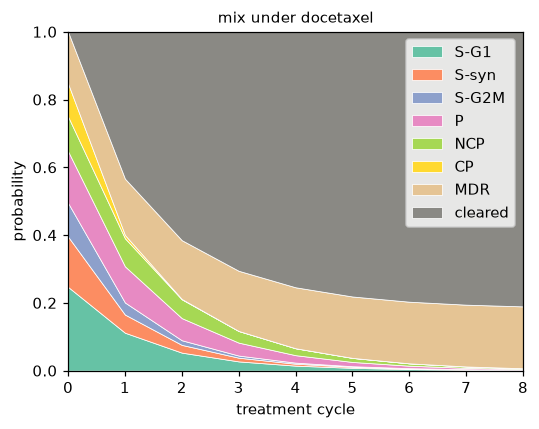

In [26]:
fig, ax = plt.subplots(figsize=(5, 4))
plot_trajectory(traj_doc, ax, "mix under docetaxel")
ax.set_ylabel("probability")
ax.legend()
plt.tight_layout(); plt.show()

1. Docetaxal works similarly to osimertinib; it clears CP, but is unable to clear MDR. MDR has a 1.0 probability, so its fully absorbing. Drug holiday doesn't absorb any states, but it causes a lot of states to potentially transition to other states. With drug holiday we can see CP being highly persistant, and a few other states being moderately persistant.

2. Under multiple rounds of Docetaxel, MDR starts to take over and persists over Docetaxel. It slightly increases from where it had started, meaning it may be starting a transition to MDR, rather than beign cleared.

## 5. Drug schedule strategies

We can answer a LOT of questions about what treatment strategy is best, just based on multiplying the transition matrices $P_{osi}, P_{doc},$ and $P_{holiday}$ together. Because matrix multiplication is linear, knowing what happens to the basis vectors under each drug tells us everything we need to know about the possibilities for mixed tumors. Use the transition matrices to do the following, running **8 cycles in each schedule**:
1. Compare 8 rounds of docetaxel and 8 rounds of osimertinib (done in step 4) to an alternating drug schedule.
   - For an alternating schedule, one *pair* of cycles multiplies by $P_{osi} P_{doc}$ and is considered 2 rounds of therapy.
2. Does it matter if we start with osimertinib or docetaxel when alternating treatments for this particular tumor?
3.  In what situation would a drug holiday help clear the tumor?
4. Test different combinations of starting states and treatment plans. Write a treatment prescription based on the general patterns you see. For example, If a tumor is entirely X cell type, treat with X. You do not need to enumerate the entire state space of possibilities, but a few clear strategies should emerge. In your treatment prescription, include the number of rounds of therapy needed. Keep in mind that fewer rounds is always better for patient health, but may not sufficiently clear the tumor. You can write this as a table or a short paragraph, but include your reasoning.

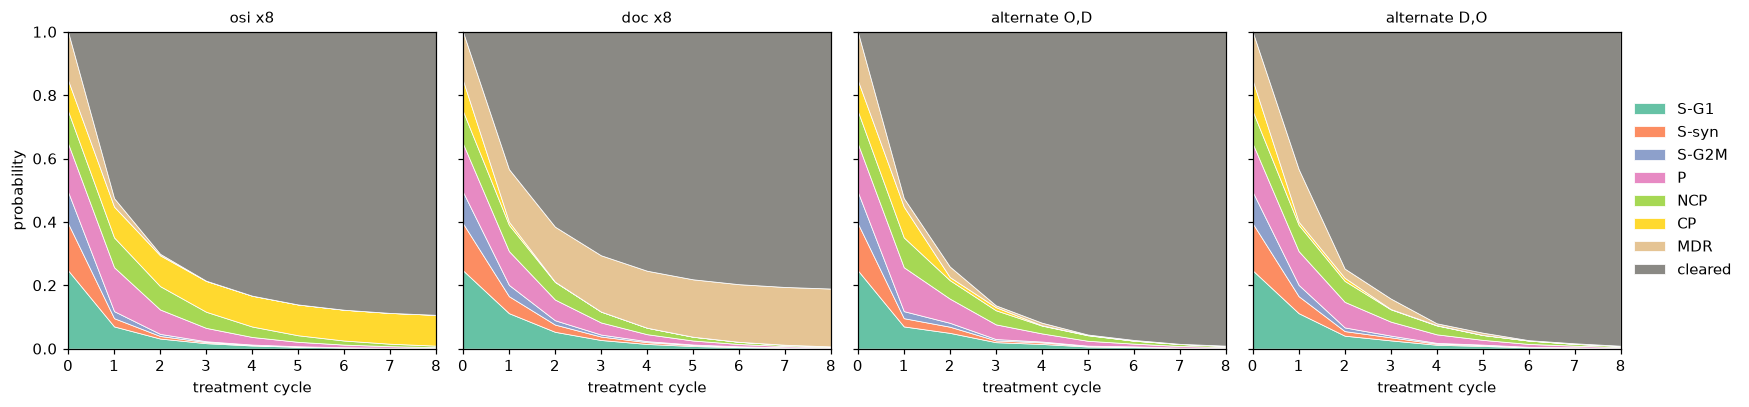

,osi x8,doc x8,"alternate O,D","alternate D,O"
S-G1,0.001,0.002,0.002,0.001
S-syn,0.000,0.001,0.001,0.000
S-G2M,0.000,0.000,0.000,0.000
P,0.003,0.002,0.003,0.003
NCP,0.005,0.002,0.003,0.004
CP,0.097,0.000,0.000,0.000
MDR,0.000,0.183,0.001,0.000
cleared,0.893,0.810,0.991,0.991
ALIVE,0.107,0.190,0.009,0.009


Do the drugs commute? False

start in MDR: fraction ALIVE at the end
  doc x4 (no holiday)    1.000
  doc,holiday x4         0.311
  osi x4 (no holiday)    0.024
  osi,holiday x4         0.014

start in CP: fraction ALIVE at the end
  doc x4 (no holiday)    0.035
  doc,holiday x4         0.019
  osi x4 (no holiday)    1.000
  osi,holiday x4         0.568

start in S-G1: fraction ALIVE at the end
  doc x4 (no holiday)    0.155
  doc,holiday x4         0.066
  osi x4 (no holiday)    0.081
  osi,holiday x4         0.030


plan,"D,O alt","O,D alt",doc,osi
start,,,,
CP,4.0,5.0,4.0,NaN
MDR,6.0,5.0,NaN,3.0
NCP,6.0,7.0,NaN,7.0
P,6.0,6.0,NaN,7.0
S-G1,6.0,5.0,NaN,5.0
S-G2M,3.0,3.0,3.0,3.0
S-syn,4.0,4.0,4.0,4.0
measured mix,6.0,5.0,NaN,NaN


,start,plan,alive@2,alive@4,alive@6,alive@8,rounds to <5%
0,S-G1,osi,0.231,0.081,0.029,0.011,5.0
1,S-G1,doc,0.370,0.155,0.093,0.073,NaN
2,S-G1,"O,D alt",0.253,0.083,0.029,0.010,5.0
3,S-G1,"D,O alt",0.278,0.091,0.031,0.011,6.0
4,S-syn,osi,0.125,0.042,0.015,0.006,4.0
5,S-syn,doc,0.144,0.045,0.020,0.012,4.0
6,S-syn,"O,D alt",0.138,0.043,0.015,0.005,4.0
7,S-syn,"D,O alt",0.134,0.040,0.014,0.005,4.0
8,S-G2M,osi,0.087,0.027,0.010,0.004,3.0
9,S-G2M,doc,0.059,0.020,0.009,0.006,3.0


In [ ]:
def run_schedule(pi0, schedule):
    '''schedule = list of matrices, one per round. Returns (len(schedule)+1, 8) trajectory.''' 
    traj = [np.asarray(pi0, dtype=float)]
    for M in schedule:
        traj.append(traj[-1] @ M)  # row-vector convention: first drug in the list is applied first 
    return np.array(traj)

N_ROUNDS = 8
sched = {
    "osi x8": [P_osi] * N_ROUNDS,
    "doc x8": [P_doc] * N_ROUNDS,
    "alternate O,D": [P_osi, P_doc] * (N_ROUNDS // 2),  # osimertinib first
    "alternate D,O": [P_doc, P_osi] * (N_ROUNDS // 2),  # docetaxel first
}

# sanity check: one pair of cycles is the single matrix P_osi @ P_doc
assert np.allclose(
    run_schedule(pi_mix, sched["alternate O,D"])[-1],
    pi_mix @ np.linalg.matrix_power(P_osi @ P_doc, N_ROUNDS // 2),
)

# --- Q1 / Q2: compare schedules on the mixed tumor ---
fig, axes = plt.subplots(1, 4, figsize=(16, 3.8), sharey=True)
for ax, (name, s) in zip(axes, sched.items()):
    plot_trajectory(run_schedule(pi_mix, s), ax, name)
axes[0].set_ylabel("probability")
axes[-1].legend(loc="center left", bbox_to_anchor=(1, 0.5), frameon=False)
plt.tight_layout()
plt.show()

summary = pd.DataFrame(
    {name: run_schedule(pi_mix, s)[-1] for name, s in sched.items()},
    index=OUTCOMES,
).round(3)
summary.loc["ALIVE"] = (1 - summary.loc["cleared"]).round(3)
display(summary)
print("Do the drugs commute?", np.allclose(P_osi @ P_doc, P_doc @ P_osi))

# --- Q3: does a drug holiday help? same number of DRUG rounds, with a holiday between  (restored)
holiday_plans = {
    "doc x4 (no holiday)": [P_doc] * 4,
    "doc,holiday x4": [P_doc, P_holiday] * 4,
    "osi x4 (no holiday)": [P_osi] * 4,
    "osi,holiday x4": [P_osi, P_holiday] * 4,
}
for start in ["MDR", "CP", "S-G1"]:
    print(f"\nstart in {start}: fraction ALIVE at the end")
    for name, s in holiday_plans.items():
        end = run_schedule(basis(start, P_hat), s)[-1]
        print(f"  {name:22s} {1 - end[-1]:.3f}")

# --- Q4: scan starting states x plans x number of rounds ---
def make_plan(kind, n):
    if kind == "osi":
        return [P_osi] * n
    if kind == "doc":
        return [P_doc] * n
    if kind == "O,D alt":
        return [P_osi if i % 2 == 0 else P_doc for i in range(n)]  
    if kind == "D,O alt":
        return [P_doc if i % 2 == 0 else P_osi for i in range(n)] 
    raise ValueError(f"unknown plan kind: {kind}")

starts = {s: basis(s, P_hat) for s in STATES}
starts["measured mix"] = pi_mix

rows = []
for sname, pi0 in starts.items():
    for kind in ["osi", "doc", "O,D alt", "D,O alt"]:
        row = {"start": sname, "plan": kind}
        for n in [2, 4, 6, 8]:
            row[f"alive@{n}"] = 1 - run_schedule(pi0, make_plan(kind, n))[-1, -1]
        # fewest rounds to get below 5% alive (None if not reached by 8)
        row["rounds to <5%"] = next(
            (n for n in range(1, 9)
             if 1 - run_schedule(pi0, make_plan(kind, n))[-1, -1] < 0.05), 
            None,
        )
        rows.append(row)

scan = pd.DataFrame(rows).round(3)
display(scan.pivot(index="start", columns="plan", values="rounds to <5%"))
display(scan)


1. After 8 cycles, alternating between osimertinib and docetaxel was the most effective treatment schedule with 99.1% probability.
2. It does not make a difference whether we start with osimertinib or docetaxel. After 8 cycles, both showed the 99.1% probability for effectiveness.
3. A drug holiday could help clear a tumor by between each drug. For example, when the cells states are not in abosrbing states, that is when drug holiday can absorb into other states letting the other treatments a easier way to eliminate the cells they're not able to.
4. Results found in table above. The best courses of action are:
- Docetaxel for CP (row 21)
- Osimertinib for MDR, (row 24)
- Either for S-G2M or S-syn (both drugs work equally well here in under 4 rounds)
- Osimertinib for S-G1 (row 0)
- Alternate with Docetxel first for P or NCP (rows 15 and 19)
- Alterate with Osimertinib first for mixed or unknown (row 30)

## 4 · Simulate a tumor as collections of random walks

*For this section, use P = P_holiday to see how the cells would evolve without drug.*

The matrix calculation tracks *probabilities*. A **random walk tracks *one cell***: at each cycle, draw a random number and use the current row of $P$ to pick the next state. Many of the questions we are interested can be answered directly with the transition matrix. However, sometimes we are curious about the path of the cells overtime. For example, if the number of times we are in a particular state is meaningful, we need to count up that over time *for each individual cell* rather than considering overall probabilities. 

The row $P_{i\cdot}$ is a discrete distribution, so sampling from it is the **inverse-CDF method** from the CDF class: draw $U \sim \text{Uniform}(0,1)$ and pick the first state whose cumulative probability exceeds $U$.

For example, if the current row is
$(0.10, 0.03, 0.02, 0.20, 0.05, 0, 0, 0.60)$, the cumulative sums are
$(0.10, 0.13, 0.15, 0.35, 0.40, 0.40, 0.40, 1.00)$. A draw of $U = 0.31$
lands in the fourth interval, $(0.15, 0.35]$, so the next state is `P`.

In [39]:
rng = np.random.default_rng(100)

In [40]:
def step(i, P, rng):
    '''Given current state index i, draw the next state index.'''
    return int(rng.choice(len(P[i]), p=P[i]))


def random_walk(start, P, n_cycles, rng):
    '''Return a list of n_cycles + 1 state indices, beginning with start.'''
    path = [start]
    for _ in range(n_cycles):
        path.append(step(path[-1], P, rng))
    return path

In [41]:
P = np.array(P_holiday) #set P equal to the numpy array of the transition matrix from the untreated experiment    
start = OUTCOMES.index("S-G1")
for _ in range(5):
    print(" -> ".join(OUTCOMES[i] for i in random_walk(start, P, 8, rng)))

S-G1 -> S-syn -> S-G2M -> S-G1 -> S-G1 -> cleared -> cleared -> cleared -> cleared
S-G1 -> S-syn -> S-syn -> cleared -> cleared -> cleared -> cleared -> cleared -> cleared
S-G1 -> cleared -> cleared -> cleared -> cleared -> cleared -> cleared -> cleared -> cleared
S-G1 -> S-G2M -> S-G2M -> S-G2M -> S-G1 -> S-G1 -> S-G1 -> S-syn -> S-G1
S-G1 -> S-G1 -> S-syn -> S-G1 -> S-syn -> S-G1 -> S-syn -> S-G2M -> S-G1


Now run **100 walks from the mixed tumor** and look at them all at once.
Each walk's *starting* state is itself drawn from $\pi_{mix}$ with the same
inverse-CDF trick. Each row of the picture is one cell (sorted by starting
state); each column is one treatment cycle.

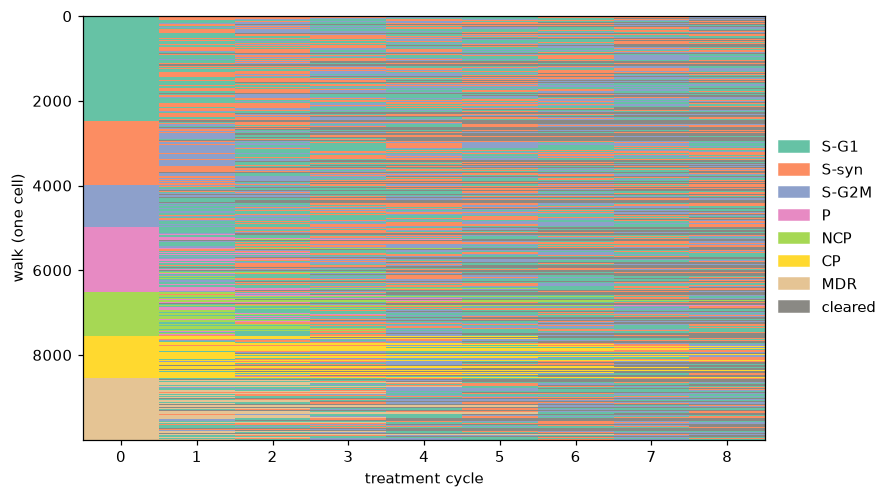

In [45]:
N_WALKS = 10000
starts = rng.choice(len(pi_mix), size=N_WALKS, p=pi_mix)
walks = np.array([random_walk(int(s0), P, N_CYCLES, rng) for s0 in starts])
walks = walks[np.argsort(walks[:, 0], kind="stable")]   # group rows by starting state

from matplotlib.colors import ListedColormap
fig, ax = plt.subplots(figsize=(8, 5))
ax.imshow(walks, cmap=ListedColormap([STATE_COLORS[s] for s in OUTCOMES]),
          vmin=-0.5, vmax=len(OUTCOMES) - 0.5, aspect="auto", interpolation="nearest")
ax.set_xlabel("treatment cycle"); ax.set_ylabel("walk (one cell)")
handles = [plt.Rectangle((0, 0), 1, 1, color=STATE_COLORS[s]) for s in OUTCOMES]
ax.legend(handles, OUTCOMES, loc="center left", bbox_to_anchor=(1, 0.5), frameon=False)
plt.show()

**Compare the two methods.** The fraction of walks in each state at cycle $t$
is an estimate of $\pi_t$. Plot both.

In [46]:
frac = np.array([[np.mean(walks[:, t] == j) for j in range(len(OUTCOMES))]
                 for t in range(N_CYCLES + 1)])

sem = np.array([[np.std(walks[:, t] == j)/np.sqrt(len(walks)) for j in range(len(OUTCOMES))]
                 for t in range(N_CYCLES + 1)])

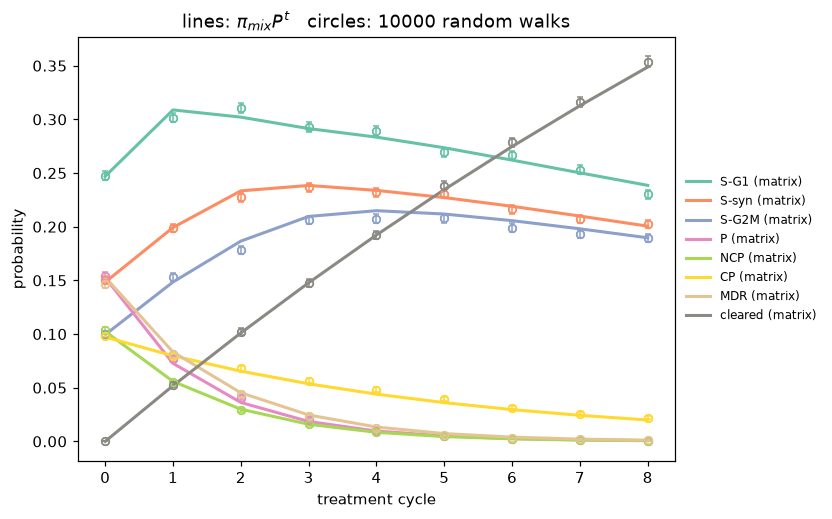

In [47]:
exact = evolve(pi_mix, P, N_CYCLES)
t = np.arange(N_CYCLES + 1)
fig, ax = plt.subplots(figsize=(7, 5))
for j, s in enumerate(OUTCOMES):
    ax.plot(t, exact[:, j], color=STATE_COLORS[s], lw=2, label=f"{s} (matrix)")
    ax.plot(t, frac[:, j], "o", color=STATE_COLORS[s], ms=5, mfc="none")
    ax.errorbar(t, frac[:, j], yerr=sem[:, j], fmt="o", color=STATE_COLORS[s],
            ms=5, mfc="none", capsize=2, elinewidth=1)
ax.set_xlabel("treatment cycle"); ax.set_ylabel("probability")
ax.set_title(f"lines: $\\pi_{{mix}} P^t$   circles: {N_WALKS} random walks")
ax.legend(loc="center left", bbox_to_anchor=(1, 0.5), frameon=False, fontsize=8)
plt.show()

We just simulated a tumor with 100 cells in it, and watched how it would evolve under no drug (drug holiday). Let's consider a different sized tumor.

<div class = 'alert alert-info'><b>Question:</b>

Re-run the last three cells with `N_WALKS = 10_000`. How does the gap between the circles and the lines change? Why?</div>

The gap between the circles and lines gets much tighter. More walks allows error to shrink. 

## 5. What's the probability a drug will clear a tumor?

We've seen in a few different ways how to understand the dynamics of cells within one tumor. We can simulate many tumors in a similar way. This allows us to interpret the likely paths of whole tumors under different treatment options and investigate things like how often cells switch states or linger in the same state.

In [54]:
def simulate_tumor(pi0, P, n_cells, n_cycles, rng):
    '''Return an array of the final state index of each of n_cells cells. Each
    cell's starting state is drawn from pi0.'''
    pi0 = np.asarray(pi0, dtype=float)
    P = np.asarray(P, dtype=float)
    starts = rng.choice(len(pi0), size=n_cells, p=pi0)
    return np.array([random_walk(int(s0), P, n_cycles, rng)[-1] for s0 in starts])

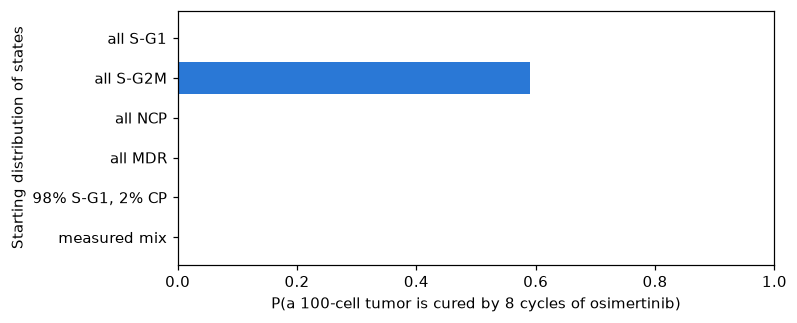

,P(cured),mean surviving cells,share of survivors that are CP
start,,,
all S-G1,0.00,7.425,0.0
all S-G2M,0.59,0.580,0.0
all NCP,0.00,7.035,0.0
all MDR,0.00,100.000,0.0
"98% S-G1, 2% CP",0.00,7.010,0.0
measured mix,0.00,18.975,0.0


In [55]:
N_CELLS, N_TUMORS = 100, 200
# P_TUMOR, N_TUMOR_CYCLES = P_osi, 8      # this simulation: 8 cycles of osimertinib

P_TUMOR, N_TUMOR_CYCLES = P_doc, 8      # this simulation: 8 cycles of docetaxel

scenarios = {
    "all S-G1":       basis("S-G1", P_hat),
    "all S-G2M":      basis("S-G2M", P_hat),
    "all NCP":         basis("NCP", P_hat),
    "all MDR":        basis("MDR", P_hat),
    "98% S-G1, 2% CP": 0.98 * basis("S-G1", P_hat) + 0.02 * basis("CP", P_hat),
    "measured mix":   pi_mix,
}
rows = []
for name, pi0 in scenarios.items():
    finals = np.array([simulate_tumor(pi0, P_TUMOR, N_CELLS, N_TUMOR_CYCLES, rng) for _ in range(N_TUMORS)])
    alive = (finals != OUTCOMES.index("cleared")).sum(axis=1)
    rows.append({"start": name,
                 "P(cured)": np.mean(alive == 0),
                 "mean surviving cells": alive.mean(),
                 "share of survivors that are CP":
                     (finals == OUTCOMES.index("CP")).sum() / max(alive.sum(), 1)})
results = pd.DataFrame(rows).set_index("start")

fig, ax = plt.subplots(figsize=(7, 3))
ax.barh(results.index[::-1], results["P(cured)"][::-1], color="#2a78d6")
ax.set_xlim(0, 1)
ax.set_xlabel(f"P(a {N_CELLS}-cell tumor is cured by {N_TUMOR_CYCLES} cycles of osimertinib)")
ax.set_ylabel("Starting distribution of states")
plt.show()
results.round(3)

<div class="alert alert-info"> Try rerunning the above code with all docetaxel. What do the results look like? </div>

With all Doxetaxel, the mean surviving cells increases with all of the starting states, and the share or survivors that is CP goes down to 0.0. In the graph above, we can see that S-G2M is the only state that has some probability that the 8 cycles will clear it. 

## 6. Investigating the persister state

Something important about the persister cells (P and NCP) not yet included in this model is their ability to pick up *permanent* mutations that allow them to be *permanently resistant (PR).* In other words, if a cell stays in the persister state for too long, it will switch to a new absorbing state not in our data. We don't have this in our dataset, so we can't estimate the transition probability of P -> PR or NCP -> PR to add it to our matrix.

We know that if a cell stays in P or NCP for too long, it will eventually become permanently resistant. We will incorporate this into the model by assuming that **if a P or NCP cell stays in a persister state for 3 or more cycles, it will become permanently resistant.** So we want to look at the random walks of cells themselves and see what percentage of cells in a tumor stay in P or NCP for **3 or more** drug cycles. 

Let's look at 100 tumors of 1000 cells each under osimertinib treatment over 8 cycles. 

In [ ]:
# write a function that runs 1000 random walks and saves them
# you will use this function 100 times to generate a simulated set of tumors

# go through each random walk and if a persister stays for 3+ consecutive cycles, add to tally
# count up cells that stayed in persister state consecutively out of total cells

# repeat for all tumors

# report mean +/- SEM for osimertinib

# compare to 10% threshold using 95% CI or a hypothesis test

In [58]:
from scipy import stats

PERSISTERS = [OUTCOMES.index("P"), OUTCOMES.index("NCP")]
N_CELLS_T, N_TUMORS_T, N_CYC, RUN = 1000, 100, 8, 3

# --- run n_cells random walks through a schedule (one matrix per cycle) and save them ---
def simulate_walks(pi0, schedule, n_cells, rng):
    '''Return an (n_cells, len(schedule)+1) array of state indices. Same inverse-CDF
    method as step(), but all cells advance at once.'''
    pi0 = np.asarray(pi0, dtype=float)
    state = rng.choice(len(pi0), size=n_cells, p=pi0)
    walks = [state]
    for M in schedule:
        M = np.asarray(M, dtype=float)                         
        cdf = np.cumsum(M, axis=1)[state]                        # each cell's row, cumulated
        u = rng.random(n_cells)[:, None]
        state = np.minimum((u > cdf).sum(axis=1), M.shape[0] - 1)   # first state with cdf >= u
        walks.append(state)
    return np.array(walks).T

# --- which cells have become permanently resistant (PR), as a function of cycle? ---
def pr_by_cycle(walks):
    '''Fraction of cells that have spent 3+ CONSECUTIVE cycles in P/NCP, by cycle 1..n.
    Counts post-treatment states only (columns 1..n), and P->NCP counts as staying a persister.'''
    is_pers = np.isin(walks[:, 1:], PERSISTERS)
    run = np.zeros(len(walks), dtype=int)
    reached = np.zeros_like(is_pers)
    for t in range(is_pers.shape[1]):
        run = (run + 1) * is_pers[:, t]                         # consecutive-run counter
        reached[:, t] = run >= RUN
    reached = np.maximum.accumulate(reached, axis=1)            # once PR, always PR
    return reached.mean(axis=0)                                 # shape (n_cycles,)

# --- repeat for all tumors ---
def simulate_tumors(pi0, schedule):
    return np.array([pr_by_cycle(simulate_walks(pi0, schedule, N_CELLS_T, rng))
                     for _ in range(N_TUMORS_T)])               # shape (n_tumors, n_cycles)

pr_osi = simulate_tumors(pi_mix, [P_osi] * N_CYC)

# --- report mean +/- SEM for osimertinib (after 8 cycles) ---
final = pr_osi[:, -1]
mean, sem = final.mean(), final.std(ddof=1) / np.sqrt(len(final))
print(f"osimertinib, {N_CYC} cycles: PR fraction = {mean:.3f} +/- {sem:.3f} (SEM)")

# --- compare to 10% threshold using 95% CI and a hypothesis test ---
lo, hi = mean - 1.96 * sem, mean + 1.96 * sem
print(f"95% CI: ({lo:.3f}, {hi:.3f})  ->  {'excludes' if (lo > .10 or hi < .10) else 'includes'} 0.10")
t, p = stats.ttest_1samp(final, 0.10)
print(f"one-sample t-test vs 0.10: t = {t:.2f}, p = {p:.3g}")
print(f"fraction of tumors with >10% PR cells: {np.mean(final > 0.10):.2f}")

osimertinib, 8 cycles: PR fraction = 0.083 +/- 0.001 (SEM)
95% CI: (0.082, 0.085)  ->  excludes 0.10
one-sample t-test vs 0.10: t = -18.51, p = 6.44e-34
fraction of tumors with >10% PR cells: 0.01


In [59]:
plans = {
    "osimertinib":       [P_osi] * N_CYC,
    "docetaxel":         [P_doc] * N_CYC,
    "alternating O,D":   [P_osi, P_doc] * (N_CYC // 2),
    "docetaxel+holiday": [P_doc, P_holiday] * (N_CYC // 2),
}
out = {name: simulate_tumors(pi_mix, s) for name, s in plans.items()}

table = pd.DataFrame({name: (r > 0.10).mean(axis=0) for name, r in out.items()},
                     index=range(1, N_CYC + 1))
table.index.name = "cycles"
display((table * 100).round(0))     # % of tumors with >10% PR cells, by number of cycles

,osimertinib,docetaxel,"alternating O,D",docetaxel+holiday
cycles,,,,
1,0.0,0.0,0.0,0.0
2,0.0,0.0,0.0,0.0
3,0.0,0.0,0.0,0.0
4,0.0,0.0,0.0,0.0
5,1.0,0.0,0.0,0.0
6,3.0,0.0,0.0,0.0
7,4.0,0.0,1.0,0.0
8,4.0,0.0,1.0,0.0


<div class="alert alert-info"> What percentage of tumors under the following treatments have more than 10% permanently resistant cells? How does this change as you increase the number of cycles?

- Osimertinib alone
- Doxetaxel alone
- Alternating OD
- Doxetaxel with drug holiday
</div>

Osimertinib is the only treatment that will have permanently resisting cells over 10%. This percentage increases as the number of cycles increases. At cycle 4, 1% of tumors exceed 10% resistant cells, and at cycle 6, 2% exceed this metric. All of the other treatments do not have tumors that sxceed 10% PR cells in this test. 